In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

#  1. Load and merge data

In [23]:
train = pd.read_csv("/kaggle/input/competitions/rossmann-store-sales/train.csv", parse_dates=["Date"])
store = pd.read_csv("/kaggle/input/competitions/rossmann-store-sales/store.csv")
df = train.merge(store, on="Store")
df = df[df["Open"] == 1].sort_values(["Store", "Date"])

/tmp/ipykernel_49/3799897658.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  train = pd.read_csv("/kaggle/input/competitions/rossmann-store-sales/train.csv", parse_dates=["Date"])


In [24]:
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)

# 2. Data quality checks

In [25]:
print("Shape:", df.shape)
print("Date range:", df.Date.min(), "->", df.Date.max())
print("Stores:", df.Store.nunique())
df.info()
df.describe().T

Shape: (844392, 18)
Date range: 2013-01-01 00:00:00 -> 2015-07-31 00:00:00
Stores: 1115
<class 'pandas.core.frame.DataFrame'>
Index: 844392 entries, 1014980 to 1114
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   Store                      844392 non-null  int64         
 1   DayOfWeek                  844392 non-null  int64         
 2   Date                       844392 non-null  datetime64[ns]
 3   Sales                      844392 non-null  int64         
 4   Customers                  844392 non-null  int64         
 5   Open                       844392 non-null  int64         
 6   Promo                      844392 non-null  int64         
 7   StateHoliday               844392 non-null  object        
 8   SchoolHoliday              844392 non-null  int64         
 9   StoreType                  844392 non-null  object        
 10  Assortment                 84

,count,mean,min,25%,50%,75%,max,std
Store,844392.0,558.42292,1.0,280.0,558.0,837.0,1115.0,321.731914
DayOfWeek,844392.0,3.520361,1.0,2.0,3.0,5.0,7.0,1.723689
Date,844392,2014-04-11 01:02:42.487565312,2013-01-01 00:00:00,2013-08-16 00:00:00,2014-03-31 00:00:00,2014-12-10 00:00:00,2015-07-31 00:00:00,NaN
Sales,844392.0,6955.514291,0.0,4859.0,6369.0,8360.0,41551.0,3104.21468
Customers,844392.0,762.728395,0.0,519.0,676.0,893.0,7388.0,401.227674
Open,844392.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0
Promo,844392.0,0.446352,0.0,0.0,0.0,1.0,1.0,0.497114
SchoolHoliday,844392.0,0.19358,0.0,0.0,0.0,0.0,1.0,0.395103
CompetitionDistance,842206.0,5457.979627,20.0,710.0,2320.0,6890.0,75860.0,7809.437311
CompetitionOpenSinceMonth,575773.0,7.224879,1.0,4.0,8.0,10.0,12.0,3.210144


In [26]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])

print("\nShare of closed days:", (df.Open == 0).mean().round(3))
print("Sales == 0 when open:", ((df.Open == 1) & (df.Sales == 0)).sum())
print("Sales == 0 when closed:", ((df.Open == 0) & (df.Sales == 0)).sum())

Missing values:
 CompetitionDistance            2186
CompetitionOpenSinceMonth    268619
CompetitionOpenSinceYear     268619
Promo2SinceWeek              423307
Promo2SinceYear              423307
PromoInterval                423307
dtype: int64

Share of closed days: 0.0
Sales == 0 when open: 54
Sales == 0 when closed: 0


In [27]:
# Missing dates per store (gaps in the calendar)
full_days = (df.Date.max() - df.Date.min()).days + 1
days_per_store = df.groupby("Store").Date.nunique()
print("\nStores with missing dates:", (days_per_store < full_days).sum())


Stores with missing dates: 1105


In [28]:
# Work with open days only for the analysis below
open_df = df[(df.Open == 1) & (df.Sales > 0)].copy()

# 3. Sales distribution and outliers

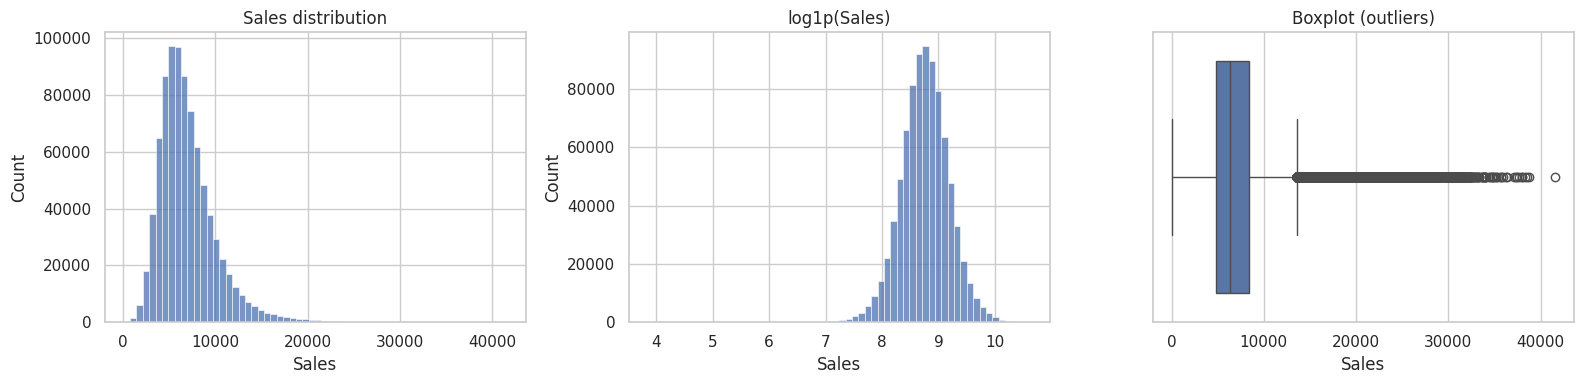

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(open_df.Sales, bins=60, ax=ax[0]).set_title("Sales distribution")
sns.histplot(np.log1p(open_df.Sales), bins=60, ax=ax[1]).set_title("log1p(Sales)")
sns.boxplot(x=open_df.Sales, ax=ax[2]).set_title("Boxplot (outliers)")
plt.tight_layout()
plt.show()

In [30]:
q1, q3 = open_df.Sales.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = open_df[open_df.Sales > q3 + 3 * iqr]
print("Extreme outliers:", len(outliers))

Extreme outliers: 5998


# 4. Total sales over time

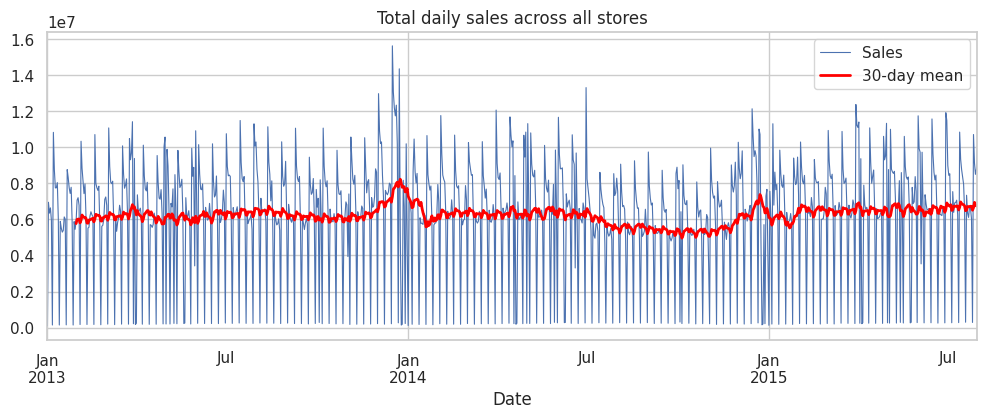

In [31]:
daily_total = open_df.groupby("Date").Sales.sum()

fig, ax = plt.subplots()
daily_total.plot(ax=ax, lw=0.8)
daily_total.rolling(30).mean().plot(ax=ax, lw=2, color="red", label="30-day mean")
ax.set_title("Total daily sales across all stores")
ax.legend()
plt.show()

# 5. A few individual stores

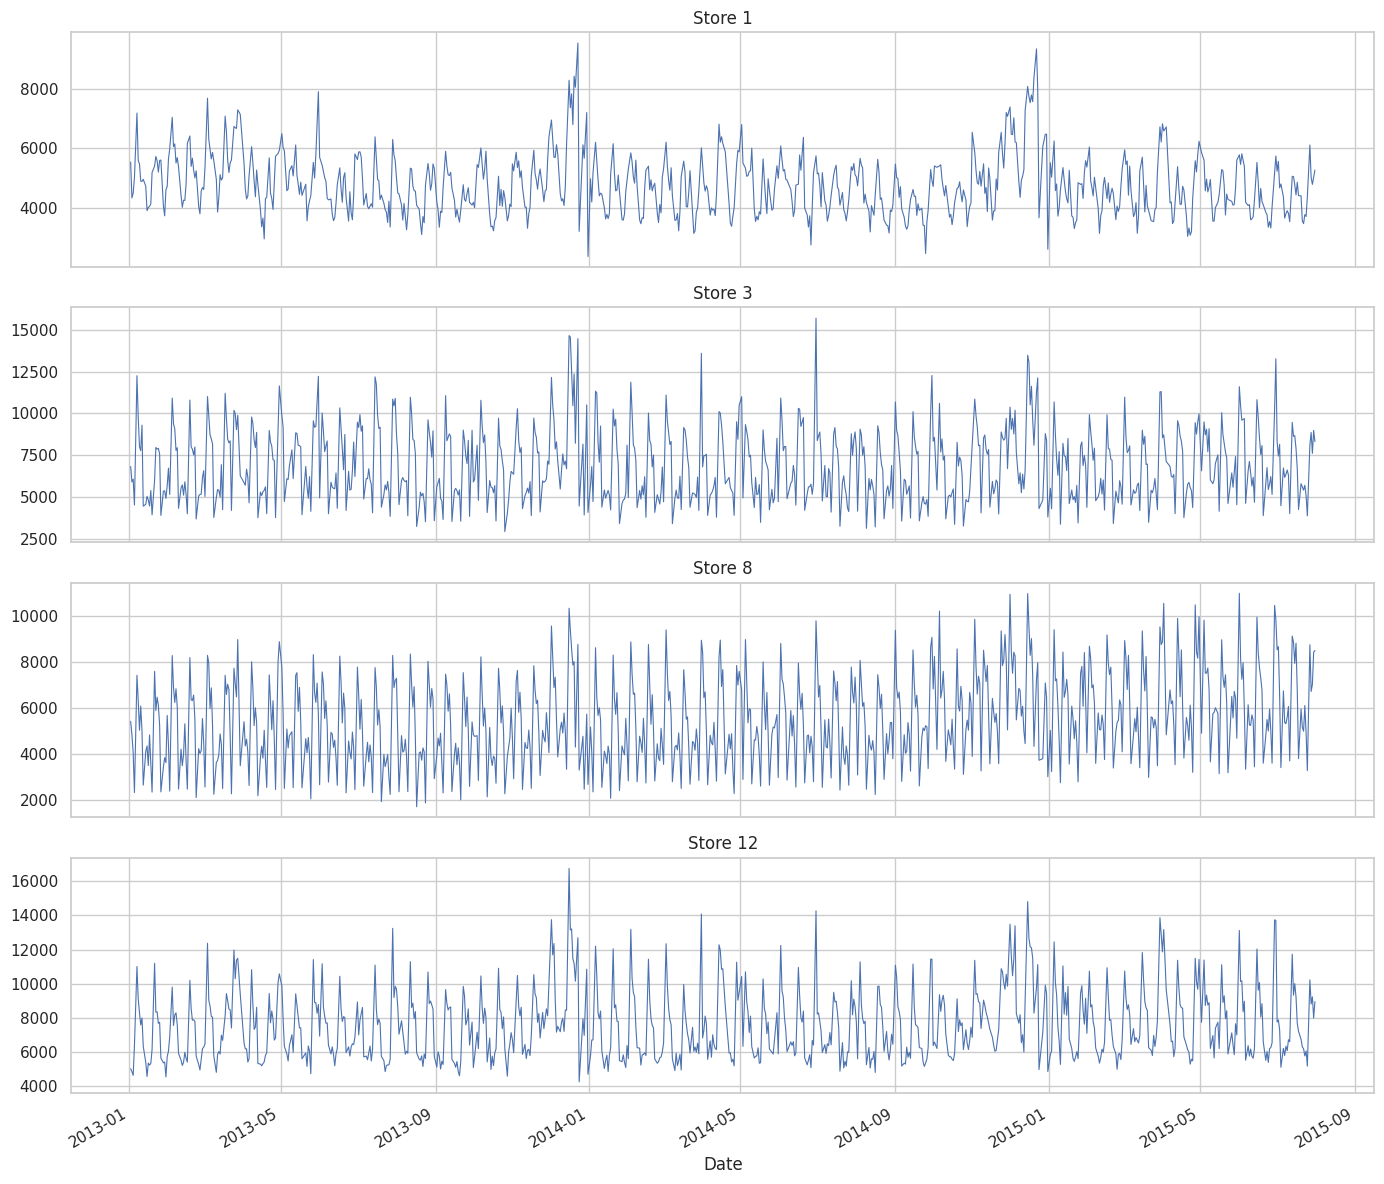

In [32]:
sample_stores = [1, 3, 8, 12]
fig, axes = plt.subplots(len(sample_stores), 1, figsize=(14, 3 * len(sample_stores)), sharex=True)
for ax, s in zip(axes, sample_stores):
    d = df[(df.Store == s) & (df.Open == 1)].set_index("Date").Sales
    d.plot(ax=ax, lw=0.8)
    ax.set_title(f"Store {s}")
plt.tight_layout()
plt.show()

# 6. Seasonality: weekday, month, year, week of year

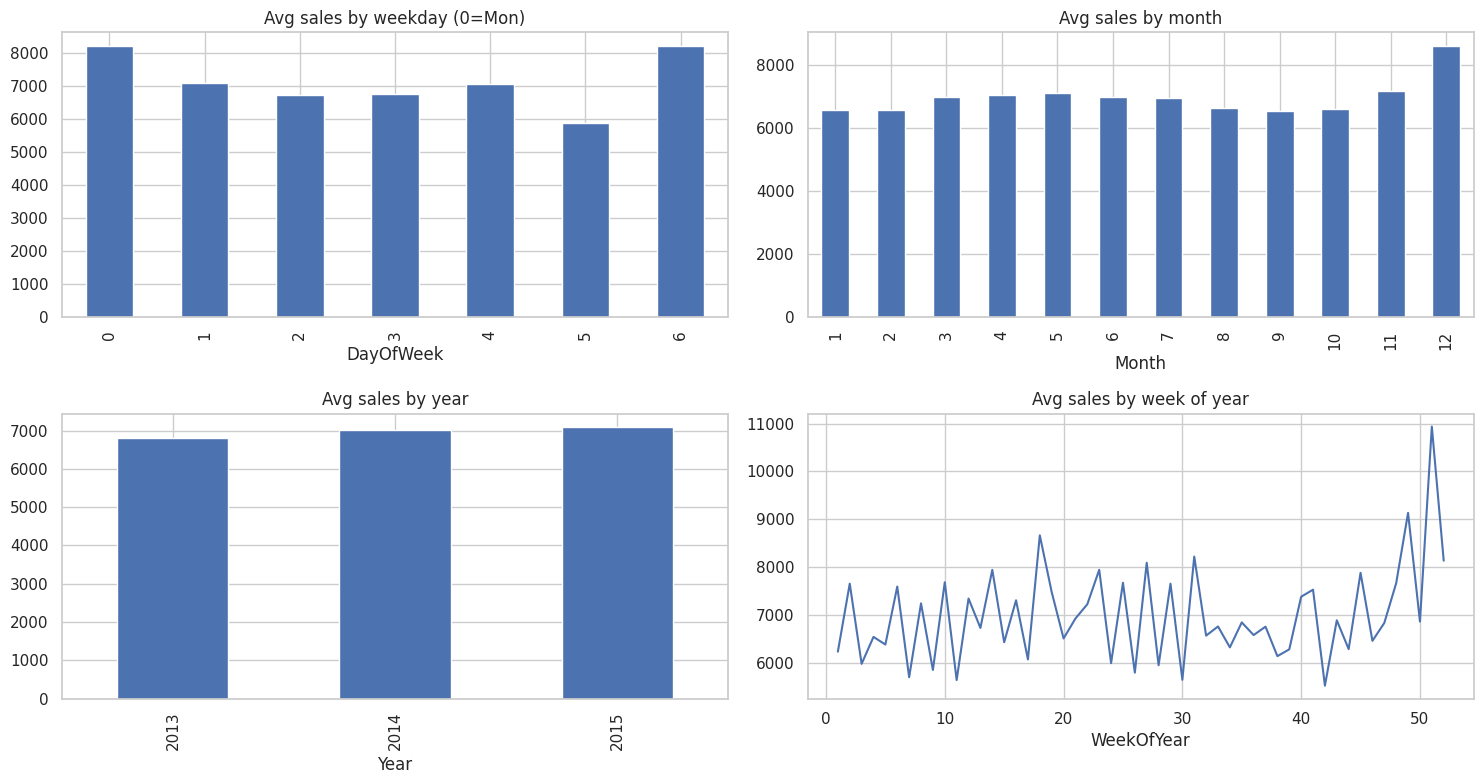

In [33]:
open_df["DayOfWeek"] = open_df.Date.dt.dayofweek
open_df["Month"] = open_df.Date.dt.month
open_df["Year"] = open_df.Date.dt.year
open_df["WeekOfYear"] = open_df.Date.dt.isocalendar().week.astype(int)

fig, ax = plt.subplots(2, 2, figsize=(15, 8))
open_df.groupby("DayOfWeek").Sales.mean().plot(kind="bar", ax=ax[0, 0], title="Avg sales by weekday (0=Mon)")
open_df.groupby("Month").Sales.mean().plot(kind="bar", ax=ax[0, 1], title="Avg sales by month")
open_df.groupby("Year").Sales.mean().plot(kind="bar", ax=ax[1, 0], title="Avg sales by year")
open_df.groupby("WeekOfYear").Sales.mean().plot(ax=ax[1, 1], title="Avg sales by week of year")
plt.tight_layout()
plt.show()

# 7. Promo, holidays, store attributes

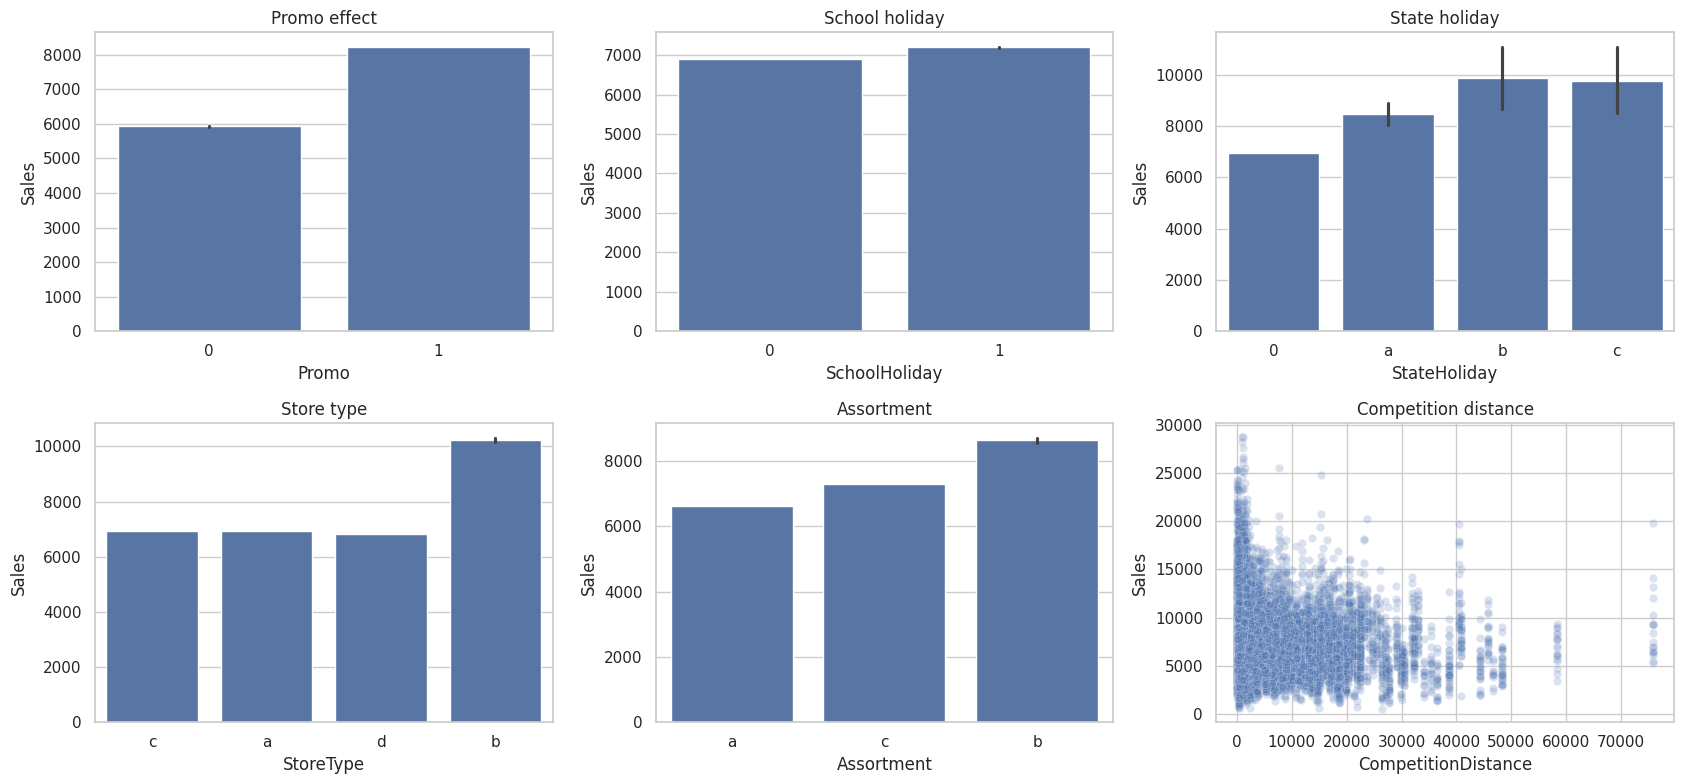

In [34]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))

sns.barplot(data=open_df, x="Promo", y="Sales", ax=ax[0, 0]).set_title("Promo effect")
sns.barplot(data=open_df, x="SchoolHoliday", y="Sales", ax=ax[0, 1]).set_title("School holiday")
sns.barplot(data=open_df, x="StateHoliday", y="Sales", ax=ax[0, 2]).set_title("State holiday")
sns.barplot(data=open_df, x="StoreType", y="Sales", ax=ax[1, 0]).set_title("Store type")
sns.barplot(data=open_df, x="Assortment", y="Sales", ax=ax[1, 1]).set_title("Assortment")
sns.scatterplot(data=open_df.sample(20000, random_state=0),
                x="CompetitionDistance", y="Sales", alpha=0.2, ax=ax[1, 2]).set_title("Competition distance")
plt.tight_layout()
plt.show()


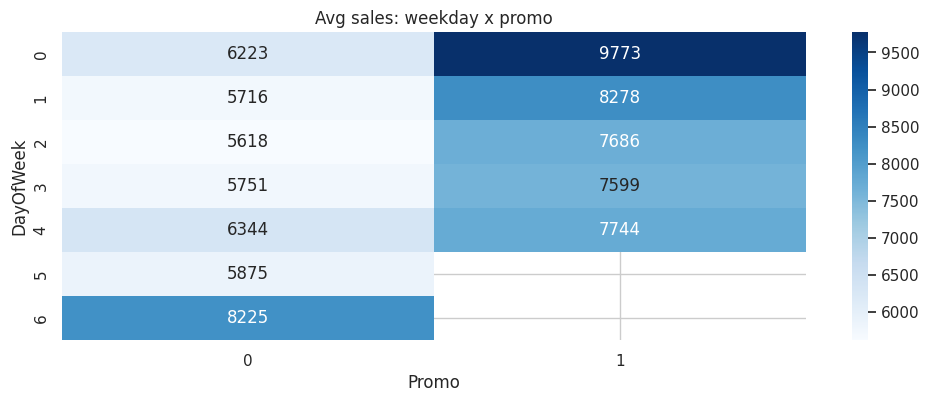

In [35]:
pivot = open_df.pivot_table(index="DayOfWeek", columns="Promo", values="Sales", aggfunc="mean")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Blues")
plt.title("Avg sales: weekday x promo")
plt.show()

# 8. Deep dive on one store: STL, stationarity, ACF/PACF

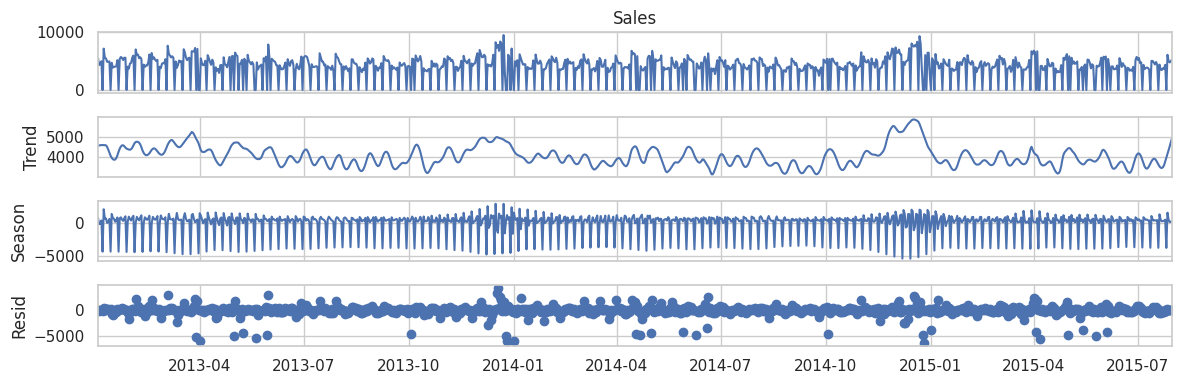

In [36]:
STORE_ID = 1
s = (df[df.Store == STORE_ID].set_index("Date").Sales
       .asfreq("D").fillna(0))          # closed days -> 0 (keeps daily frequency)

# STL decomposition with weekly period
res = STL(s, period=7, robust=True).fit()
res.plot()
plt.show()


/tmp/ipykernel_49/1125101772.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_value, *_ = adfuller(s)


ADF statistic: -4.366, p-value: 0.0003


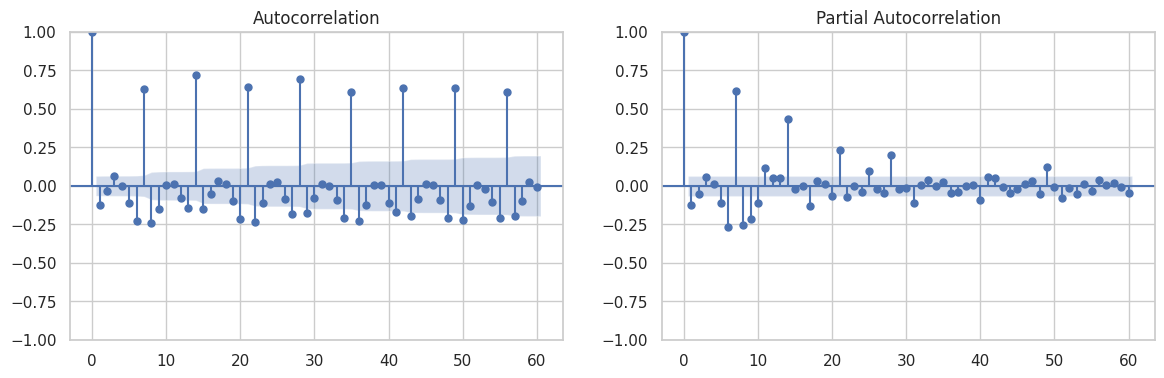

In [37]:
adf_stat, p_value, *_ = adfuller(s)
print(f"ADF statistic: {adf_stat:.3f}, p-value: {p_value:.4f}")

# Autocorrelation
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(s, lags=60, ax=ax[0])
plot_pacf(s, lags=60, ax=ax[1], method="ywm")
plt.show()

# 9. Correlations and a summary of findings

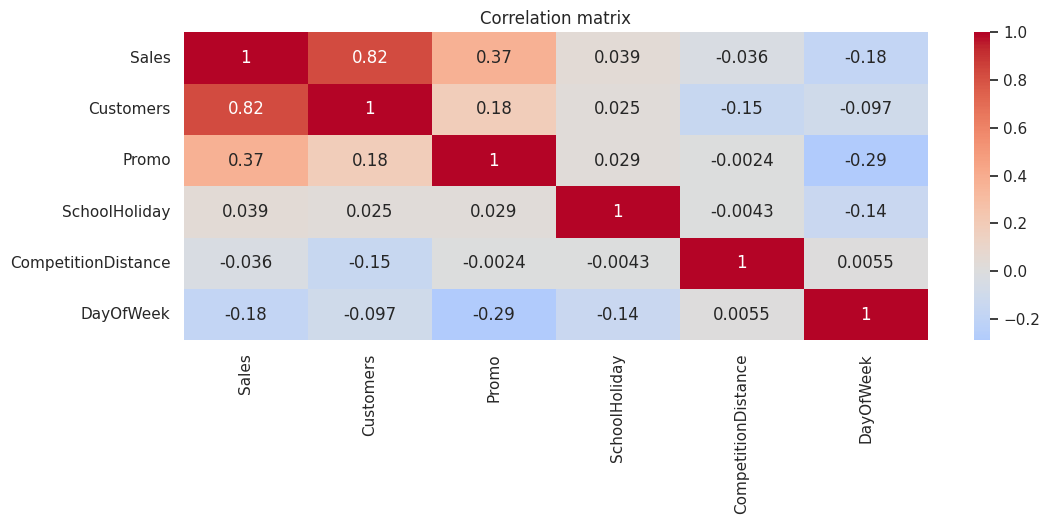

In [38]:
num_cols = ["Sales", "Customers", "Promo", "SchoolHoliday",
            "CompetitionDistance", "DayOfWeek"]
sns.heatmap(open_df[num_cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

# Keep open days with positive sales


In [39]:
df = df[(df.Open == 1) & (df.Sales > 0)].sort_values(["Store", "Date"]).reset_index(drop=True)
df["StateHoliday"] = df["StateHoliday"].astype(str)

In [40]:
# Metrics
def mae(y, p):   return np.mean(np.abs(y - p))
def rmse(y, p):  return np.sqrt(np.mean((y - p) ** 2))
def smape(y, p): return np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p))) * 100
def rmspe(y, p):
    m = y != 0
    return np.sqrt(np.mean(((y[m] - p[m]) / y[m]) ** 2))

def evaluate(y, p, name="model"):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return pd.Series({"model": name, "MAE": mae(y, p), "RMSE": rmse(y, p),
                      "sMAPE_%": smape(y, p), "RMSPE": rmspe(y, p)})

In [41]:
# Simple holdout split: last 6 weeks = validation
HORIZON_DAYS = 42
val_start = df.Date.max() - pd.Timedelta(days=HORIZON_DAYS - 1)

train_df = df[df.Date < val_start].copy()
valid_df = df[df.Date >= val_start].copy()

print("Train:", train_df.Date.min().date(), "->", train_df.Date.max().date(), len(train_df))
print("Valid:", valid_df.Date.min().date(), "->", valid_df.Date.max().date(), len(valid_df))

assert train_df.Date.max() < valid_df.Date.min()

Train: 2013-01-01 -> 2015-06-19 804056
Valid: 2015-06-20 -> 2015-07-31 40282


In [42]:
# Walk-forward validation (non-overlapping folds, split by date)
def walk_forward_splits(data, n_splits=4, horizon_days=42, gap_days=0):
    last = data.Date.max()
    for k in range(n_splits, 0, -1):
        val_end = last - pd.Timedelta(days=(k - 1) * horizon_days)
        val_start = val_end - pd.Timedelta(days=horizon_days - 1)
        train_end = val_start - pd.Timedelta(days=gap_days + 1)
        yield (data.index[data.Date <= train_end],
               data.index[(data.Date >= val_start) & (data.Date <= val_end)])

for i, (tr, va) in enumerate(walk_forward_splits(df)):
    print(f"Fold {i+1}: train to {df.loc[tr,'Date'].max().date()} | "
          f"valid {df.loc[va,'Date'].min().date()} -> {df.loc[va,'Date'].max().date()}")

Fold 1: train to 2015-02-13 | valid 2015-02-14 -> 2015-03-27
Fold 2: train to 2015-03-27 | valid 2015-03-28 -> 2015-05-08
Fold 3: train to 2015-05-08 | valid 2015-05-09 -> 2015-06-19
Fold 4: train to 2015-06-19 | valid 2015-06-20 -> 2015-07-31


In [43]:
# Reusable harness: used in Step 5 onward
def run_cv(predict_fn, data, n_splits=4, horizon_days=42, name="model"):
    rows = []
    for i, (tr, va) in enumerate(walk_forward_splits(data, n_splits, horizon_days)):
        tr_df, va_df = data.loc[tr], data.loc[va]
        s = evaluate(va_df.Sales.values, predict_fn(tr_df, va_df), name)
        s["fold"] = i + 1
        rows.append(s)
    res = pd.DataFrame(rows)
    return res, res[["MAE", "RMSE", "sMAPE_%", "RMSPE"]].mean()

# Quick test: predict each store's mean
def store_mean_predict(tr_df, va_df):
    means = tr_df.groupby("Store").Sales.mean()
    return va_df.Store.map(means).fillna(tr_df.Sales.mean()).values

folds, avg = run_cv(store_mean_predict, df, name="store_mean")
print(folds.round(3))
print(avg.round(3))

        model       MAE      RMSE  sMAPE_%  RMSPE  fold
0  store_mean  1258.232  1653.588   19.251  0.328     1
1  store_mean  1744.501  2286.590   23.694  0.339     2
2  store_mean  1334.684  1814.941   18.984  0.299     3
3  store_mean  1456.509  1934.433   21.306  0.331     4
MAE        1448.481
RMSE       1922.388
sMAPE_%      20.809
RMSPE         0.324
dtype: float64


In [44]:
# 1. Seasonal naive: last observed value for the same store and weekday
def seasonal_naive_predict(tr_df, va_df):
    tr = tr_df.assign(dow=tr_df.Date.dt.dayofweek)
    last = (tr.sort_values("Date")
              .groupby(["Store", "dow"]).Sales.last()
              .rename("pred").reset_index())
    va = va_df.assign(dow=va_df.Date.dt.dayofweek)
    out = va.merge(last, on=["Store", "dow"], how="left")["pred"]
    return out.fillna(tr_df.Sales.mean()).values

In [45]:

# 2. Seasonal average: mean of the last K same-weekday values (smoother than naive)
def make_seasonal_avg(k=4):
    def predict(tr_df, va_df):
        tr = tr_df.assign(dow=tr_df.Date.dt.dayofweek).sort_values("Date")
        avg = (tr.groupby(["Store", "dow"]).Sales
                 .apply(lambda s: s.tail(k).mean())
                 .rename("pred").reset_index())
        va = va_df.assign(dow=va_df.Date.dt.dayofweek)
        out = va.merge(avg, on=["Store", "dow"], how="left")["pred"]
        return out.fillna(tr_df.Sales.mean()).values
    return predict

In [46]:
# 3. Moving average: mean of each store's last N open days (ignores weekday)
def make_moving_avg(n=28):
    def predict(tr_df, va_df):
        ma = (tr_df.sort_values("Date").groupby("Store").Sales
                   .apply(lambda s: s.tail(n).mean()))
        return va_df.Store.map(ma).fillna(tr_df.Sales.mean()).values
    return predict

In [47]:
# 4. Promo-aware seasonal baseline: last K values for same store, weekday AND promo status
def make_seasonal_promo_avg(k=4):
    def predict(tr_df, va_df):
        tr = tr_df.assign(dow=tr_df.Date.dt.dayofweek).sort_values("Date")
        avg = (tr.groupby(["Store", "dow", "Promo"]).Sales
                 .apply(lambda s: s.tail(k).mean())
                 .rename("pred").reset_index())
        fallback = (tr.groupby(["Store", "dow"]).Sales
                      .apply(lambda s: s.tail(k).mean())
                      .rename("fb").reset_index())
        va = va_df.assign(dow=va_df.Date.dt.dayofweek)
        out = va.merge(avg, on=["Store", "dow", "Promo"], how="left")
        out = out.merge(fallback, on=["Store", "dow"], how="left")
        return out["pred"].fillna(out["fb"]).fillna(tr_df.Sales.mean()).values
    return predict

In [48]:
# 5. Run all baselines through walk-forward CV
baselines = {
    "store_mean":          store_mean_predict,          # from Step 4
    "moving_avg_28":       make_moving_avg(28),
    "seasonal_naive":      seasonal_naive_predict,
    "seasonal_avg_4":      make_seasonal_avg(4),
    "seasonal_promo_avg_4": make_seasonal_promo_avg(4),
}

summary, fold_results = [], []
for name, fn in baselines.items():
    folds, avg = run_cv(fn, df, n_splits=4, horizon_days=42, name=name)
    fold_results.append(folds)
    row = avg.to_dict()
    row["RMSPE_std"] = folds["RMSPE"].std()
    row["model"] = name
    summary.append(row)

baseline_table = (pd.DataFrame(summary).set_index("model")
                    .sort_values("RMSPE").round(4))
print(baseline_table)

                            MAE       RMSE  sMAPE_%   RMSPE  RMSPE_std
model                                                                 
seasonal_promo_avg_4   823.8585  1209.5898  11.6470  0.1757     0.0359
seasonal_avg_4        1229.3192  1637.1535  17.1614  0.2373     0.0208
seasonal_naive        1525.5446  2128.0160  21.5044  0.2957     0.0461
moving_avg_28         1434.3127  1886.1573  20.5763  0.3222     0.0244
store_mean            1448.4815  1922.3882  20.8088  0.3242     0.0172


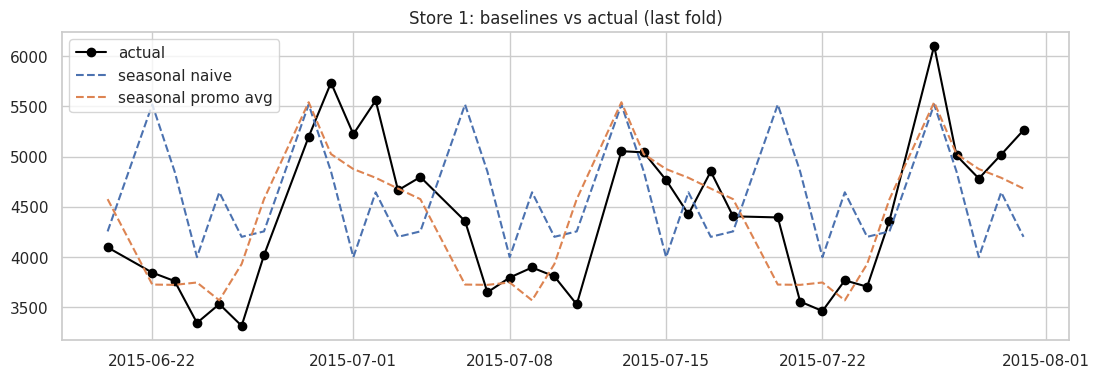

In [49]:
# 6. Plot predictions vs actuals for one store (last fold)
import matplotlib.pyplot as plt

STORE_ID = 1
tr_idx, va_idx = list(walk_forward_splits(df, 4, 42))[-1]
tr_df, va_df = df.loc[tr_idx], df.loc[va_idx]
v = va_df[va_df.Store == STORE_ID].sort_values("Date").copy()

v["seasonal_naive"] = seasonal_naive_predict(tr_df, va_df)[va_df.Store.values == STORE_ID][
    np.argsort(va_df[va_df.Store == STORE_ID].Date.values)]
v["seasonal_promo_avg"] = make_seasonal_promo_avg(4)(tr_df, va_df)[va_df.Store.values == STORE_ID][
    np.argsort(va_df[va_df.Store == STORE_ID].Date.values)]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(v.Date, v.Sales, "o-", label="actual", color="black")
ax.plot(v.Date, v.seasonal_naive, "--", label="seasonal naive")
ax.plot(v.Date, v.seasonal_promo_avg, "--", label="seasonal promo avg")
ax.set_title(f"Store {STORE_ID}: baselines vs actual (last fold)")
ax.legend()
plt.show()

In [51]:
# 7. Save the benchmark to beat
baseline_table.to_csv("/kaggle/working/baseline_results.csv")
best = baseline_table.index[0]
print(f"Best baseline: {best} | RMSPE = {baseline_table.loc[best, 'RMSPE']:.4f}")

Best baseline: seasonal_promo_avg_4 | RMSPE = 0.1757


In [57]:
!pip install statsforecast

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [statsforecast]0m [statsforecast]


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS, AutoARIMA

In [59]:
# 1. Build a regular daily series for one store (closed days kept as 0)
STORE_ID = 1

raw = pd.read_csv("/kaggle/input/competitions/rossmann-store-sales/train.csv", parse_dates=["Date"], low_memory=False)
s = raw[raw.Store == STORE_ID].sort_values("Date").set_index("Date")[["Sales", "Open", "Promo"]]
s = s.asfreq("D").fillna(0)                      # fill any missing calendar days

ts = s.reset_index().rename(columns={"Date": "ds", "Sales": "y"})
ts["unique_id"] = STORE_ID

print(ts.ds.min().date(), "->", ts.ds.max().date(), "| days:", len(ts))

2013-01-01 -> 2015-07-31 | days: 942


In [60]:
# 2. Cross-validation with the same folds as Step 4
models = [
    SeasonalNaive(season_length=7),
    AutoETS(season_length=7),
    AutoARIMA(season_length=7),
]
sf = StatsForecast(models=models, freq="D", n_jobs=-1)

cv = sf.cross_validation(
    df=ts[["unique_id", "ds", "y"]],
    h=42,              # 6-week horizon
    step_size=42,      # non-overlapping folds
    n_windows=4,       # 4 folds
)

# Closed days are known in advance: score open days only, clip negatives
model_cols = ["SeasonalNaive", "AutoETS", "AutoARIMA"]
cv = cv.merge(ts[["ds", "Open"]], on="ds")
cv[model_cols] = cv[model_cols].clip(lower=0)
cv_open = cv[(cv.Open == 1) & (cv.y > 0)].copy()

In [61]:
# 3. Score each model per fold (uses evaluate() from Step 4)
rows = []
for fold, (cutoff, g) in enumerate(cv_open.groupby("cutoff"), start=1):
    for m in model_cols:
        r = evaluate(g.y.values, g[m].values, m)
        r["fold"] = fold
        rows.append(r)

res = pd.DataFrame(rows)
classical_table = (res.groupby("model")[["MAE", "RMSE", "sMAPE_%", "RMSPE"]]
                      .mean().sort_values("RMSPE").round(4))
print(classical_table)

                    MAE       RMSE  sMAPE_%   RMSPE
model                                              
AutoETS        691.0829   834.6076  15.1978  0.1774
AutoARIMA      698.9100   842.6944  15.3580  0.1943
SeasonalNaive  853.4634  1050.4127  18.9651  0.2203


In [62]:
# 4. Compare with the Step 5 baseline on the SAME store
store_df = df[df.Store == STORE_ID].reset_index(drop=True)
_, base_avg = run_cv(make_seasonal_promo_avg(4), store_df, name="seasonal_promo_avg_4")

comparison = pd.concat(
    [classical_table, base_avg.round(4).to_frame("seasonal_promo_avg_4").T]
).sort_values("RMSPE")
print(comparison)

                           MAE       RMSE  sMAPE_%   RMSPE
seasonal_promo_avg_4  541.4309   715.0167  11.7991  0.1639
AutoETS               691.0829   834.6076  15.1978  0.1774
AutoARIMA             698.9100   842.6944  15.3580  0.1943
SeasonalNaive         853.4634  1050.4127  18.9651  0.2203


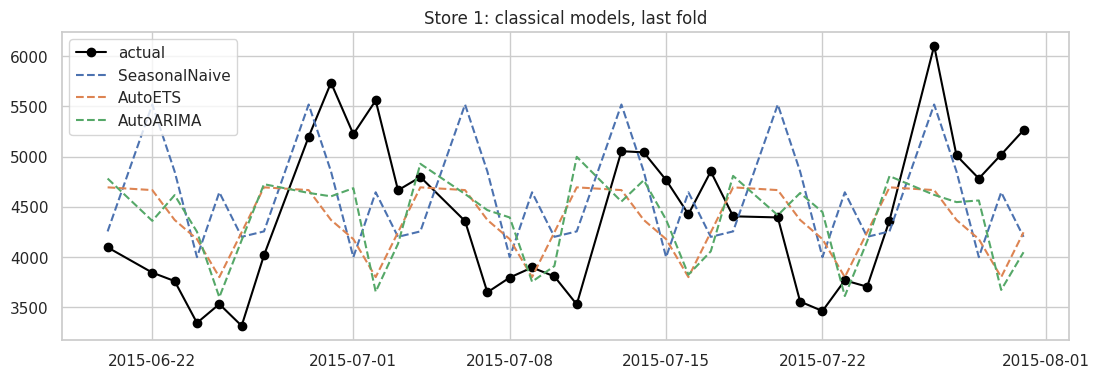

In [63]:
# 5. Plot the last fold: actual vs each model
last = cv_open[cv_open.cutoff == cv_open.cutoff.max()]

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(last.ds, last.y, "o-", color="black", label="actual")
for m in model_cols:
    ax.plot(last.ds, last[m], "--", label=m)
ax.set_title(f"Store {STORE_ID}: classical models, last fold")
ax.legend()
plt.show()

In [65]:
# 6. Bonus: ARIMA with Promo as an external regressor
# Promo schedules are known in advance, so using them is not leakage.
# Needs a recent statsforecast; extra columns in df are treated as exogenous.
sf_x = StatsForecast(models=[AutoARIMA(season_length=7)], freq="D", n_jobs=-1)
cv_x = sf_x.cross_validation(
    df=ts[["unique_id", "ds", "y", "Promo"]],
    h=42, step_size=42, n_windows=4,
)
cv_x = cv_x.merge(ts[["ds", "Open"]], on="ds")
cv_x["AutoARIMA"] = cv_x["AutoARIMA"].clip(lower=0)
cv_x = cv_x[(cv_x.Open == 1) & (cv_x.y > 0)]
res_x = evaluate(cv_x.y.values, cv_x.AutoARIMA.values, "AutoARIMA+Promo")
print(res_x.drop("model").astype(float).round(4))


MAE        520.5283
RMSE       670.6821
sMAPE_%     11.6177
RMSPE        0.1487
dtype: float64


In [66]:
# 7. Scale to several stores (each store gets its own model)
STORES = [1, 3, 8, 12, 25, 40, 77, 100, 250, 500]

multi = raw[raw.Store.isin(STORES)].sort_values(["Store", "Date"])
parts = []
for sid, g in multi.groupby("Store"):
    g = g.set_index("Date")[["Sales", "Open"]].asfreq("D").fillna(0).reset_index()
    g["unique_id"] = sid
    parts.append(g.rename(columns={"Date": "ds", "Sales": "y"}))
multi_ts = pd.concat(parts, ignore_index=True)

sf_m = StatsForecast(models=[SeasonalNaive(7), AutoETS(season_length=7)], freq="D", n_jobs=-1)
cv_m = sf_m.cross_validation(df=multi_ts[["unique_id", "ds", "y"]], h=42, step_size=42, n_windows=4)
cv_m = cv_m.merge(multi_ts[["unique_id", "ds", "Open"]], on=["unique_id", "ds"])
cv_m = cv_m[(cv_m.Open == 1) & (cv_m.y > 0)]
for m in ["SeasonalNaive", "AutoETS"]:
    r = evaluate(cv_m.y.values, cv_m[m].clip(lower=0).values, m)
    print(m, r.drop("model").astype(float).round(4).to_dict())

SeasonalNaive {'MAE': 1603.8043, 'RMSE': 2235.0959, 'sMAPE_%': 21.9222, 'RMSPE': 0.282}
AutoETS {'MAE': 1299.9392, 'RMSE': 1704.5895, 'sMAPE_%': 17.3582, 'RMSPE': 0.2085}


In [67]:
# 8. Save results
comparison.to_csv("/kaggle/working/classical_results.csv")

In [69]:
H = 42   # forecast horizon in days
# ---------------------------------------------------------
# 1. Full daily calendar per store (so shifts are in DAYS, not rows)
# ---------------------------------------------------------
raw = pd.read_csv("/kaggle/input/competitions/rossmann-store-sales/train.csv", parse_dates=["Date"], low_memory=False)
store = pd.read_csv("/kaggle/input/competitions/rossmann-store-sales/store.csv")
raw["StateHoliday"] = raw["StateHoliday"].astype(str)

dates = pd.date_range(raw.Date.min(), raw.Date.max(), freq="D")
grid = pd.MultiIndex.from_product([raw.Store.unique(), dates],
                                  names=["Store", "Date"]).to_frame(index=False)

full = grid.merge(raw.drop(columns="Customers"), on=["Store", "Date"], how="left")
full = full.sort_values(["Store", "Date"]).reset_index(drop=True)

# Rows missing from train.csv (e.g. stores closed for refurbishment)
full["Open"] = full["Open"].fillna(0).astype(int)
full["Promo"] = full["Promo"].fillna(0).astype(int)
full["SchoolHoliday"] = full["SchoolHoliday"].fillna(0).astype(int)
full["StateHoliday"] = full["StateHoliday"].fillna("0")

# Sales that count: open days with positive sales, otherwise NaN
full["Sales_open"] = full["Sales"].where((full.Open == 1) & (full.Sales > 0))
print(full.shape)

(1050330, 9)


In [70]:
# ---------------------------------------------------------
# 2. Calendar features (always known)
# ---------------------------------------------------------
d = full["Date"]
full["dayofweek"] = d.dt.dayofweek
full["day"] = d.dt.day
full["month"] = d.dt.month
full["quarter"] = d.dt.quarter
full["weekofyear"] = d.dt.isocalendar().week.astype(int)
full["dayofyear"] = d.dt.dayofyear
full["is_month_start"] = d.dt.is_month_start.astype(int)
full["is_month_end"] = d.dt.is_month_end.astype(int)

In [71]:
# ---------------------------------------------------------
# 3. Distance to / from events (promo, holidays) - all known in advance
# ---------------------------------------------------------
def add_event_distance(frame, flag, name):
    """days since the last event day and days until the next one, per store."""
    tmp = frame["Date"].where(flag)
    prev_ev = tmp.groupby(frame["Store"]).ffill()
    next_ev = tmp.groupby(frame["Store"]).bfill()
    frame[f"days_since_{name}"] = (frame["Date"] - prev_ev).dt.days
    frame[f"days_to_{name}"] = (next_ev - frame["Date"]).dt.days

add_event_distance(full, full.StateHoliday != "0", "state_holiday")
add_event_distance(full, full.SchoolHoliday == 1, "school_holiday")
add_event_distance(full, full.Promo == 1, "promo")

full["state_holiday_flag"] = (full.StateHoliday != "0").astype(int)

In [72]:
# ---------------------------------------------------------
# 4. Store attributes
# ---------------------------------------------------------
store["CompetitionDistance"] = store["CompetitionDistance"].fillna(store["CompetitionDistance"].max())
store["has_competition_date"] = store["CompetitionOpenSinceYear"].notna().astype(int)

# Promo2 start date (approximate: first day of the ISO week)
store["Promo2Start"] = (
    pd.to_datetime(store["Promo2SinceYear"].astype("Int64").astype("string") + "-01-01", errors="coerce")
    + pd.to_timedelta((store["Promo2SinceWeek"].fillna(1) - 1) * 7, unit="D")
)
store["PromoInterval"] = store["PromoInterval"].fillna("").str.replace("Sept", "Sep")

full = full.merge(store, on="Store", how="left")

# Months since the nearest competitor opened (0 if unknown or not yet open)
comp_months = ((full.Date.dt.year - full.CompetitionOpenSinceYear) * 12
               + (full.Date.dt.month - full.CompetitionOpenSinceMonth))
full["competition_months"] = comp_months.clip(lower=0).fillna(0)

# Is the Promo2 campaign active in this month?
month_abbr = full.Date.dt.strftime("%b")
in_interval = [m in iv.split(",") for m, iv in zip(month_abbr, full.PromoInterval)]
full["promo2_active"] = ((full.Promo2 == 1) & (full.Date >= full.Promo2Start)
                         & np.array(in_interval)).astype(int)

# Categoricals for LightGBM
for c in ["StoreType", "Assortment", "StateHoliday"]:
    full[c] = full[c].astype("category")

In [73]:
# ---------------------------------------------------------
# 5. Lag and rolling features (every shift >= H, so no leakage)
# ---------------------------------------------------------
g = full.groupby("Store")["Sales_open"]

# Weekly-aligned lags (multiples of 7 keep the same weekday)
for lag in [42, 49, 56, 63, 91, 182, 364]:
    full[f"lag_{lag}"] = g.shift(lag)

# Average of the last 4 same-weekday values available at the forecast origin
full["dow_mean_4"] = full[["lag_42", "lag_49", "lag_56", "lag_63"]].mean(axis=1)

# Rolling stats on the series shifted by H
shifted = g.shift(H)
for w in [28, 91]:
    full[f"roll_mean_{w}"] = shifted.groupby(full["Store"]).transform(
        lambda s: s.rolling(w, min_periods=7).mean())
full["roll_std_28"] = shifted.groupby(full["Store"]).transform(
    lambda s: s.rolling(28, min_periods=7).std())

# Trend: recent level vs longer-term level
full["trend_ratio"] = full["roll_mean_28"] / full["roll_mean_91"]

In [74]:
# ---------------------------------------------------------
# 7. Modeling table: open days only
# ---------------------------------------------------------
feat = full[(full.Open == 1) & (full.Sales > 0)].copy()
feat["target"] = np.log1p(feat["Sales"])          # model log1p(Sales)
feat = feat.reset_index(drop=True)

print("Rows:", len(feat), "| Date range:", feat.Date.min().date(), "->", feat.Date.max().date())

Rows: 844338 | Date range: 2013-01-01 -> 2015-07-31


In [75]:
# ---------------------------------------------------------
# 8. Store-level target statistics - computed from TRAIN ONLY, per fold
# ---------------------------------------------------------
def add_store_stats(train_part, other_parts):
    """Fit store means on train_part, attach them to train_part and every frame in other_parts."""
    tp = train_part.copy()
    stats = {
        "store_mean":        (["Store"], "store_mean"),
        "store_dow_mean":    (["Store", "dayofweek"], "store_dow_mean"),
        "store_promo_mean":  (["Store", "Promo"], "store_promo_mean"),
        "store_dow_promo_mean": (["Store", "dayofweek", "Promo"], "store_dow_promo_mean"),
    }
    tables = {name: tp.groupby(keys)["target"].mean().rename(name).reset_index()
              for name, (keys, _) in stats.items()}

    def attach(frame):
        frame = frame.copy()
        for name, (keys, _) in stats.items():
            frame = frame.merge(tables[name], on=keys, how="left")
        return frame

    return attach(tp), [attach(o) for o in other_parts]

In [76]:
# ---------------------------------------------------------
# 9. Feature list and a quick sanity check on the holdout split
# ---------------------------------------------------------
DROP = ["Sales", "Sales_open", "target", "Date", "Open", "Promo2Start",
        "PromoInterval", "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
        "Promo2SinceWeek", "Promo2SinceYear"]
STAT_FEATS = ["store_mean", "store_dow_mean", "store_promo_mean", "store_dow_promo_mean"]
FEATURES = [c for c in feat.columns if c not in DROP] + STAT_FEATS

val_start = feat.Date.max() - pd.Timedelta(days=H - 1)
tr_part = feat[feat.Date < val_start]
va_part = feat[feat.Date >= val_start]

tr_part, (va_part,) = add_store_stats(tr_part, [va_part])

print(len(FEATURES), "features")
print(tr_part[FEATURES].isna().mean().sort_values(ascending=False).head(8).round(3))

43 features
lag_364         0.441
lag_182         0.263
lag_91          0.151
lag_63          0.119
lag_56          0.109
lag_49          0.096
lag_42          0.091
roll_mean_28    0.068
dtype: float64


In [77]:
# ---------------------------------------------------------
# 10. Save for Step 8
# ---------------------------------------------------------
feat.to_parquet("/kaggle/working/features.parquet")     # pip install pyarrow if missing

In [78]:
# ---------------------------------------------------------
# 1. Fit / predict function (plugs straight into run_cv)
# ---------------------------------------------------------
PARAMS = dict(
    objective="regression",        # on log1p(Sales), so close to optimizing RMSPE
    learning_rate=0.05,
    n_estimators=3000,
    num_leaves=127,
    min_child_samples=50,
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=-1,
    verbose=-1,
)

def fit_lgb(tr_df, va_df, params=PARAMS):
    """
    Trains on tr_df, returns (model, preds_on_va_df in Sales units).
    Early stopping uses the LAST 42 days of tr_df, never the validation fold.
    """
    cut = tr_df.Date.max() - pd.Timedelta(days=H - 1)
    fit_part = tr_df[tr_df.Date < cut]
    es_part = tr_df[tr_df.Date >= cut]

    # Store statistics come from fit_part only
    fit_part, (es_part, va_part) = add_store_stats(fit_part, [es_part, va_df])

    model = lgb.LGBMRegressor(**params)
    model.fit(
        fit_part[FEATURES], fit_part["target"],
        eval_set=[(es_part[FEATURES], es_part["target"])],
        eval_metric="rmse",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    preds = np.expm1(model.predict(va_part[FEATURES]))
    return model, np.clip(preds, 0, None)

def lgb_predict(tr_df, va_df):
    return fit_lgb(tr_df, va_df)[1]

In [80]:
# ---------------------------------------------------------
# 2. Quick holdout check first (one fit, a few minutes)
# ---------------------------------------------------------
import lightgbm as lgb
val_start = feat.Date.max() - pd.Timedelta(days=H - 1)
train_part = feat[feat.Date < val_start]
valid_part = feat[feat.Date >= val_start]

model, preds = fit_lgb(train_part, valid_part)
print("Best iteration:", model.best_iteration_)
print(evaluate(valid_part.Sales.values, preds, "lgbm_holdout").drop("model").astype(float).round(4))

Best iteration: 1175
MAE         919.0560
RMSE       1196.5162
sMAPE_%      13.0468
RMSPE         0.1833
dtype: float64


In [81]:
# ---------------------------------------------------------
# 3. Walk-forward CV (4 folds, same as the baselines)
# ---------------------------------------------------------
lgb_folds, lgb_avg = run_cv(lgb_predict, feat, n_splits=4, horizon_days=H, name="lgbm")
print(lgb_folds.drop(columns="model").astype(float).round(4))
print("\nAverage:\n", lgb_avg.round(4))

        MAE       RMSE  sMAPE_%   RMSPE  fold
0  520.4195   786.3504   8.0657  0.1651   1.0
1  625.2393   901.2242   8.2289  0.1044   2.0
2  649.0659   865.0645   9.3076  0.1290   3.0
3  919.9180  1197.0299  13.0657  0.1835   4.0

Average:
 MAE        678.6607
RMSE       937.4173
sMAPE_%      9.6670
RMSPE        0.1455
dtype: float64


In [85]:
# ---------------------------------------------------------
# 4. Compare with the baselines from Step 5
# ---------------------------------------------------------
baseline_table = pd.read_csv("/kaggle/working//baseline_results.csv", index_col="model")

row = lgb_avg.to_dict()
row["RMSPE_std"] = lgb_folds["RMSPE"].astype(float).std()
final_table = pd.concat([baseline_table, pd.DataFrame([row], index=["lgbm"])]).sort_values("RMSPE")
print(final_table.round(4))

best_base = baseline_table["RMSPE"].min()
gain = (1 - lgb_avg["RMSPE"] / best_base) * 100
print(f"\nLightGBM RMSPE is {gain:.1f}% lower than the best baseline")

final_table.to_csv("/kaggle/working/model_comparison.csv")

                            MAE       RMSE  sMAPE_%   RMSPE  RMSPE_std
lgbm                   678.6607   937.4173   9.6670  0.1455     0.0355
seasonal_promo_avg_4   823.8585  1209.5898  11.6470  0.1757     0.0359
seasonal_avg_4        1229.3192  1637.1535  17.1614  0.2373     0.0208
seasonal_naive        1525.5446  2128.0160  21.5044  0.2957     0.0461
moving_avg_28         1434.3127  1886.1573  20.5763  0.3222     0.0244
store_mean            1448.4815  1922.3882  20.8088  0.3242     0.0172

LightGBM RMSPE is 17.2% lower than the best baseline


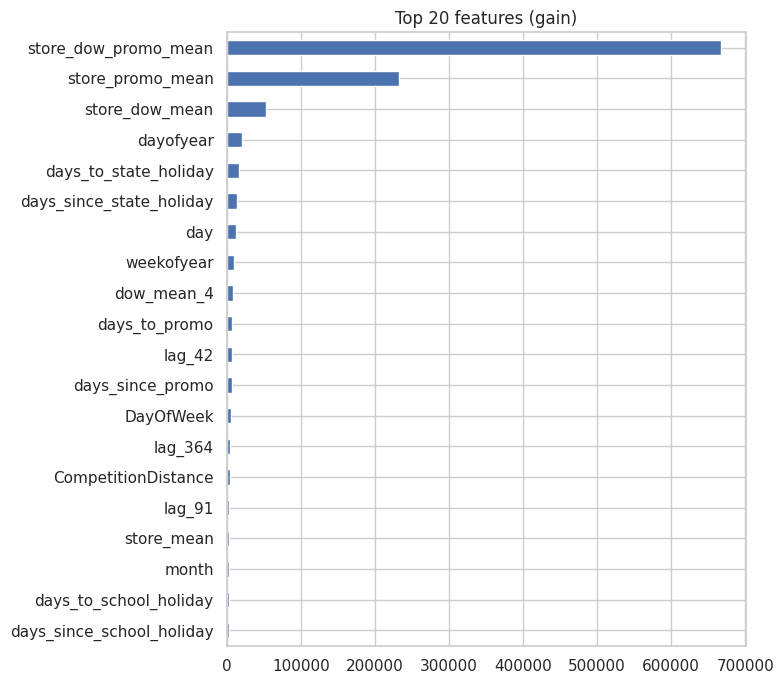

In [86]:
# ---------------------------------------------------------
# 5. Feature importance (from the holdout model)
# ---------------------------------------------------------
imp = (pd.Series(model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
         .sort_values(ascending=False))
imp.head(20)[::-1].plot(kind="barh", figsize=(8, 7), title="Top 20 features (gain)")
plt.tight_layout()
plt.show()


RMSPE by dayofweek
dayofweek
0    0.1335
1    0.1542
2    0.1925
3    0.1962
4    0.2094
5    0.2019
6    0.1620

RMSPE by Promo
Promo
0    0.1819
1    0.1852

RMSPE by StateHoliday
StateHoliday
0    0.1833

RMSPE by StoreType
StoreType
a    0.1778
b    0.1319
c    0.1878
d    0.1930

RMSPE by Assortment
Assortment
a    0.1857
b    0.1230
c    0.1815


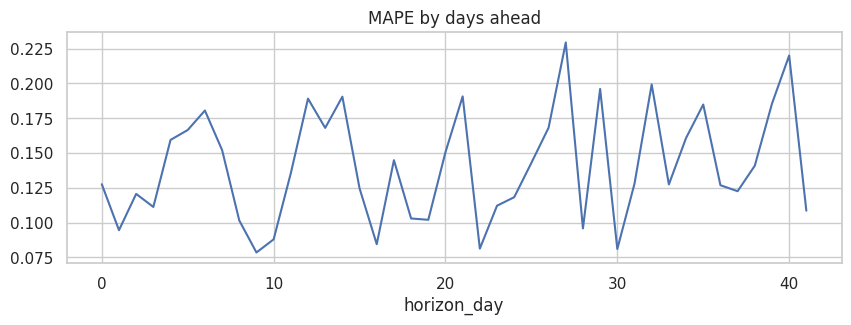


Worst 10 stores:
 Store
292     1.202
909     0.855
782     0.573
876     0.528
722     0.425
711     0.421
501     0.358
956     0.346
839     0.341
1014    0.340


In [87]:
# ---------------------------------------------------------
# 6. Error analysis on the holdout window
# ---------------------------------------------------------
ev = valid_part.assign(pred=preds)
ev["ape"] = np.abs(ev.Sales - ev.pred) / ev.Sales
ev["horizon_day"] = (ev.Date - val_start).dt.days

def rmspe_group(g):
    return np.sqrt(np.mean(((g.Sales - g.pred) / g.Sales) ** 2))

for col in ["dayofweek", "Promo", "StateHoliday", "StoreType", "Assortment"]:
    print(f"\nRMSPE by {col}")
    print(ev.groupby(col, observed=True)[["Sales", "pred"]].apply(rmspe_group).round(4).to_string())

# Does error grow with forecast horizon?
ev.groupby("horizon_day").ape.mean().plot(figsize=(10, 3), title="MAPE by days ahead")
plt.show()

# Worst stores
worst = (ev.groupby("Store")[["Sales", "pred"]].apply(rmspe_group)
           .sort_values(ascending=False).head(10))
print("\nWorst 10 stores:\n", worst.round(3).to_string())

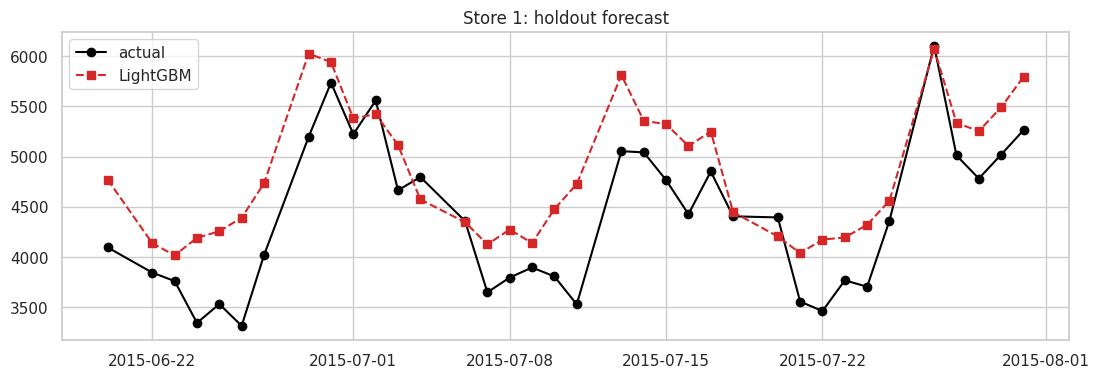

In [88]:
# ---------------------------------------------------------
# 7. Plot predictions vs actuals for one store
# ---------------------------------------------------------
STORE_ID = 1
s = ev[ev.Store == STORE_ID].sort_values("Date")
plt.figure(figsize=(13, 4))
plt.plot(s.Date, s.Sales, "o-", color="black", label="actual")
plt.plot(s.Date, s.pred, "s--", color="tab:red", label="LightGBM")
plt.title(f"Store {STORE_ID}: holdout forecast")
plt.legend()
plt.show()

In [90]:
# ---------------------------------------------------------
# 8. Save the model and the feature list for the Streamlit app (Step 12)
# ---------------------------------------------------------
import joblib
joblib.dump({"model": model, "features": FEATURES}, "/kaggle/working/lgbm_model.joblib")

['/kaggle/working/lgbm_model.joblib']